# 第088讲 CPU可复现实验
先读lecture.md与lab.md。本笔记本实际运行相同脚本、测试并显示图像；输出不是手工粘贴。

In [1]:
import sys, pathlib, subprocess, json
print(sys.version)
print('Working directory:', pathlib.Path.cwd())

3.12.14 (main, Aug 25 2026, 14:00:49) [Clang 22.1.3 ]
Working directory: /workspace/scratch/1577d0a62398/tutorials-20261019/machine-learning/units/088


In [2]:
result=subprocess.run([sys.executable,'experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout)
print('Script exit:',result.returncode)

{
  "accumulation": {
    "correct_max_abs_error": 2.9802322387695312e-08,
    "unscaled_max_abs_error": 0.32153573632240295
  },
  "resume": {
    "checkpoint_step": 57,
    "exact_max_abs_error": 0.0,
    "weights_only_max_abs_error": 0.11322782188653946
  },
  "final_val_loss": {
    "sgd": [
      0.2758931815624237,
      0.35094383358955383,
      0.28067532181739807
    ],
    "adamw": [
      0.27396589517593384,
      0.25065886974334717,
      0.21791507303714752
    ],
    "warmup": [
      0.31351238489151,
      0.349217027425766,
      0.28337907791137695
    ]
  }
}

Script exit: 0


In [3]:
result=subprocess.run([sys.executable,'-m','unittest','-v','test_experiment.py'],capture_output=True,text=True,check=True)
print(result.stdout+result.stderr)

test_accumulation (test_experiment.Tests.test_accumulation) ... ok
test_resume (test_experiment.Tests.test_resume) ... ok
test_schedule (test_experiment.Tests.test_schedule) ... ok

----------------------------------------------------------------------
Ran 3 tests in 1.330s

OK



In [4]:
data=json.loads(pathlib.Path('outputs/results.json').read_text())
print('Result fields:', list(data))

Result fields: ['environment', 'protocol', 'runs', 'accumulation', 'resume']


01_budget_schedule.png
02_accumulation.png
03_resume.png


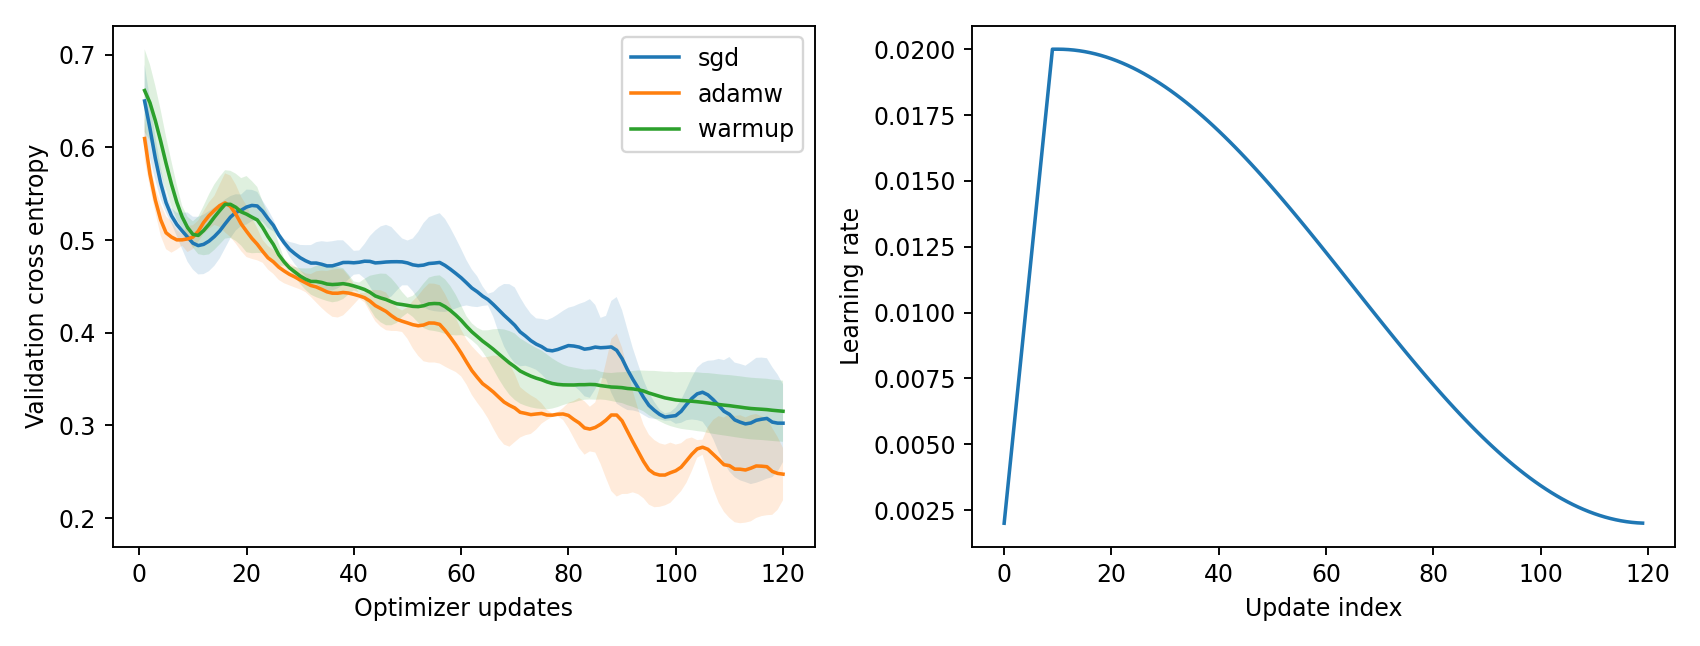

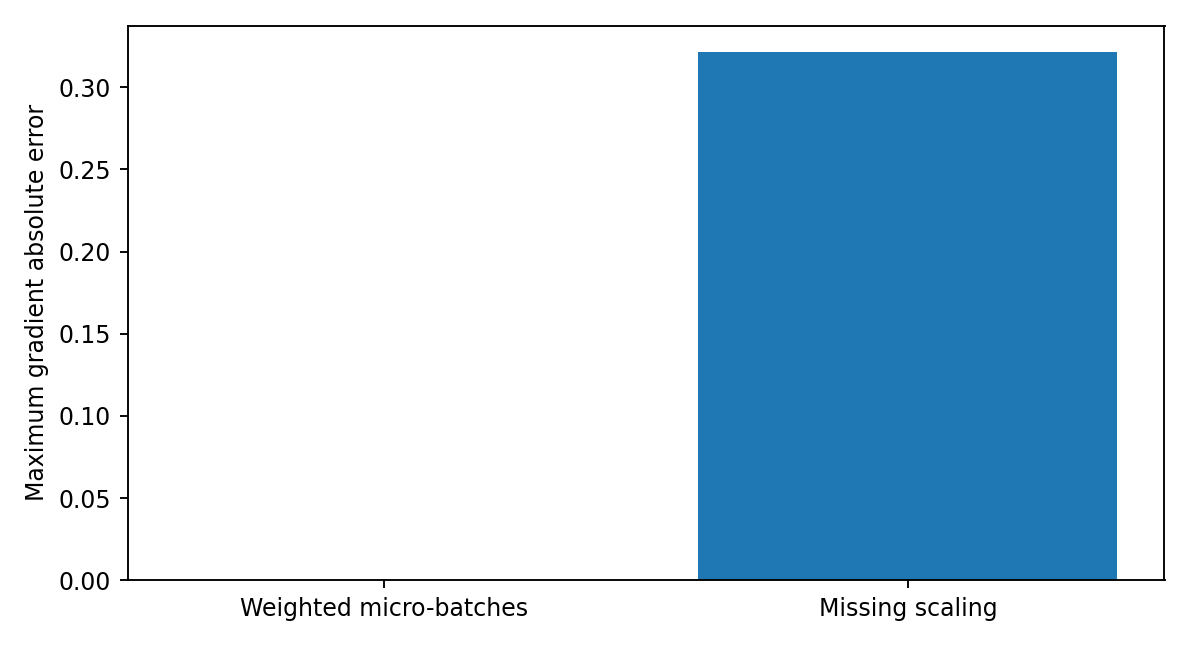

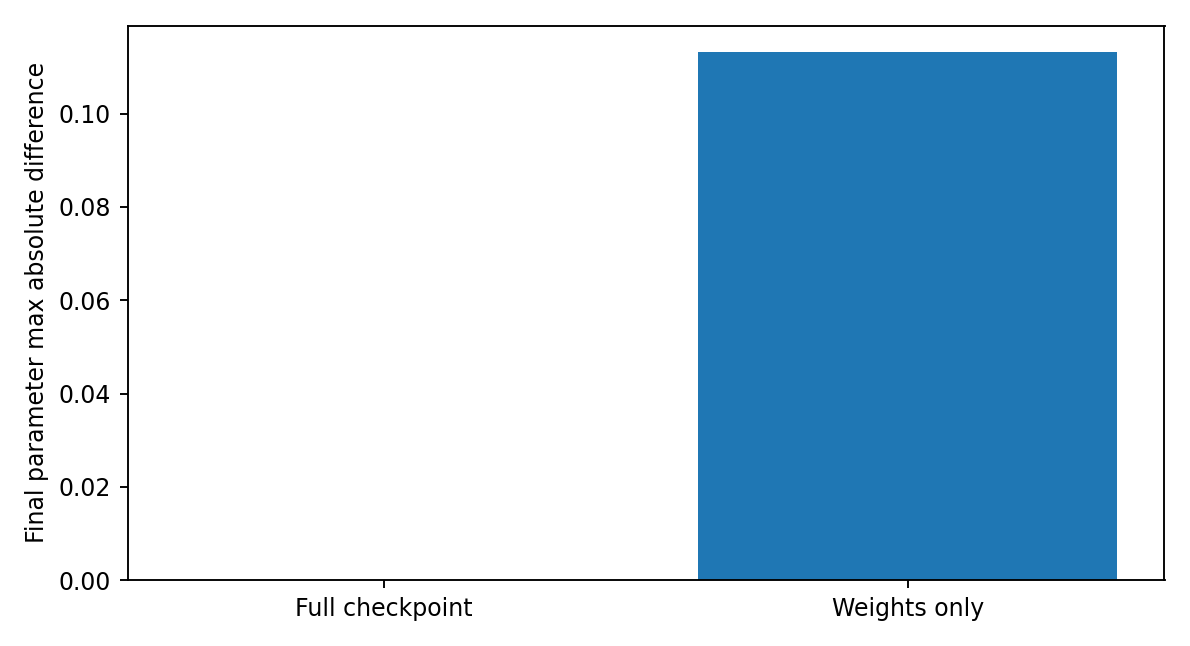

In [5]:
from IPython.display import display, Image
for p in sorted(pathlib.Path('figures').glob('*.png')):
    print(p.name)
    display(Image(filename=str(p)))

解释任务：逐项说明图中的控制变量、预算口径、失败对照和不能支持的结论。详细答案见answers.md。